<a href="https://colab.research.google.com/github/denverkim/BA_FALL2026/blob/main/BA_LAB7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# 파일 읽기
import pandas as pd

arrest = pd.read_csv('/content/USArrests.csv')
arrest.head()

,Unnamed: 0,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6


In [7]:
# 인덱스 설정
arrest.set_index('Unnamed: 0', inplace=True)
arrest.head()

,Murder,Assault,UrbanPop,Rape
Unnamed: 0,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [8]:
# scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_arrest = scaler.fit_transform(arrest)
scaled_arrest

array([[ 1.25517927,  0.79078716, -0.52619514, -0.00345116],
       [ 0.51301858,  1.11805959, -1.22406668,  2.50942392],
       [ 0.07236067,  1.49381682,  1.00912225,  1.05346626],
       [ 0.23470832,  0.23321191, -1.08449238, -0.18679398],
       [ 0.28109336,  1.2756352 ,  1.77678094,  2.08881393],
       [ 0.02597562,  0.40290872,  0.86954794,  1.88390137],
       [-1.04088037, -0.73648418,  0.79976079, -1.09272319],
       [-0.43787481,  0.81502956,  0.45082502, -0.58583422],
       [ 1.76541475,  1.99078607,  1.00912225,  1.1505301 ],
       [ 2.22926518,  0.48775713, -0.38662083,  0.49265293],
       [-0.57702994, -1.51224105,  1.21848371, -0.11129987],
       [-1.20322802, -0.61527217, -0.80534376, -0.75839217],
       [ 0.60578867,  0.94836277,  1.21848371,  0.29852525],
       [-0.13637203, -0.70012057, -0.03768506, -0.0250209 ],
       [-1.29599811, -1.39102904, -0.5959823 , -1.07115345],
       [-0.41468229, -0.67587817,  0.03210209, -0.34856705],
       [ 0.44344101, -0.

In [11]:
# PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_fit = pca.fit(scaled_arrest)
pca_fit.n_components_ #주성분 갯수

2

In [14]:
# 차원 축소
df_arrest = pca.fit_transform(scaled_arrest) #주성분
df_arrest = pd.DataFrame(df_arrest)
df_arrest.columns = ['PC1', 'PC2']
df_arrest.head()

,PC1,PC2
0,0.985566,-1.133392
1,1.950138,-1.073213
2,1.763164,0.745957
3,-0.141420,-1.119797
4,2.523980,1.542934


In [30]:
# 군집 분석
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2)
kmeans.fit(scaled_arrest)
label = kmeans.labels_
df_arrest['cluster'] = label
df_arrest.head()

,PC1,PC2,cluster
0,0.985566,-1.133392,1
1,1.950138,-1.073213,1
2,1.763164,0.745957,1
3,-0.141420,-1.119797,0
4,2.523980,1.542934,1


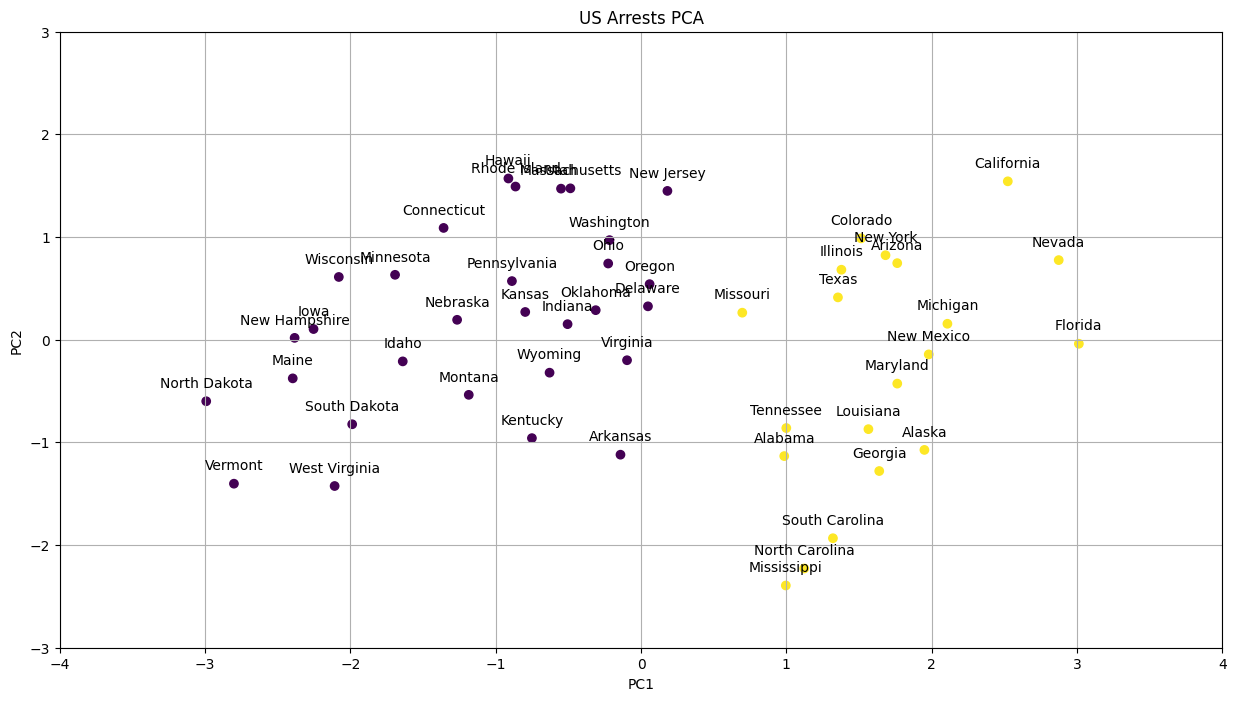

In [31]:
# 2차원 그래프
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))
plt.scatter(df_arrest['PC1'], df_arrest['PC2'], c=df_arrest.cluster)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('US Arrests PCA')
plt.grid()
plt.xlim(-4, 4)
plt.ylim(-3, 3)
for x, y, state in zip(df_arrest.PC1, df_arrest.PC2, arrest.index):
    plt.annotate(xy=[x,y], text=state, ha='center', xytext=[0,10], textcoords='offset points')
plt.show()

In [32]:
# rotation matrix
pca.components_.T

array([[ 0.53589947, -0.41818087],
       [ 0.58318363, -0.1879856 ],
       [ 0.27819087,  0.87280619],
       [ 0.54343209,  0.16731864]])

In [33]:
# explained ratio
pca.explained_variance_ratio_

array([0.62006039, 0.24744129])

In [34]:
# accumulated ratio
pca.explained_variance_ratio_.sum()

np.float64(0.8675016829223337)

In [35]:
# Plot accumulated ratio
k = range(1,5)
ratio = []
for i in k:
    pca = PCA(n_components=i).fit(arrest)
    ratio.append(pca.explained_variance_ratio_.sum())
ratio

[np.float64(0.9655342205668822),
 np.float64(0.9933515571990572),
 np.float64(0.9991510921213993),
 np.float64(1.0)]

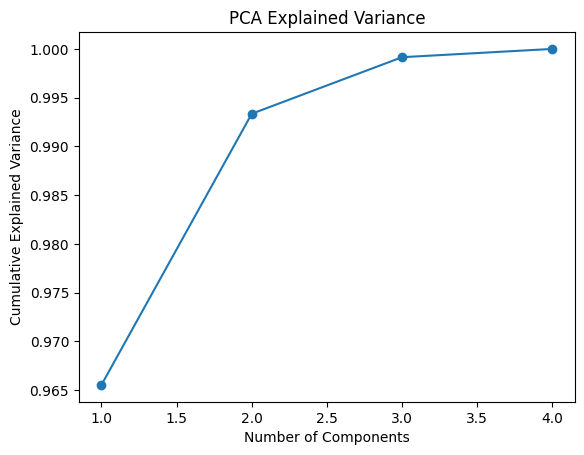

In [36]:
# accumulated ratio plot
plt.plot(k,ratio, marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Explained Variance')
plt.show()